In [1]:
import pandas as pd
import numpy as np
import copepodTCR as cpp
import seaborn as sn
from matplotlib import pyplot as plt

## plotting styles
plt.style.use('default')
color_basic = '#FFA500'
color_copepodTCR = '#015396'

## formula to calculate sensitivity and specificity based on the number of true-false positive-negatives
def calculate_tpr_fpr(tp, tn, fp, fn):

    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)

    return tpr, 1 - fpr

# Figure 6A

Percentage of simulations with a correctly identified set of cognate (overlapping
or not) peptides with and without experimental errors, modeled as false negative pools. Bar plots show the
percentage of simulations in which all true cognate (no false positives) were assigned by the decision-tree
algorithm to the “cognate” list. The black line on each bar shows the 95% confidence interval, measured
using bootstrapping with 1,000 samples.

In [2]:
## DATA: simulations with negative share fixed in 0.5-0.7 and 0.7-0.9 intervals
results = pd.read_csv('./data/insilico-simulations_methods-comparison_fixed-negshare.tsv', sep='\t')

## calculating sensitivity and specificity
tpr, fpr = calculate_tpr_fpr(results['TruePositive'], results['TrueNegative'], results['FalsePositive'], results['FalseNegative'])
results['Sensitivity'] = tpr
results['Specificity'] = fpr

## control == 0 activated pools
control = results[results['error'] == 100]
## with simulated 1 error
table_error = results[results['error'] == 1]
## with simulated 0 errors
table_noerror = results[results['error'] == 0]

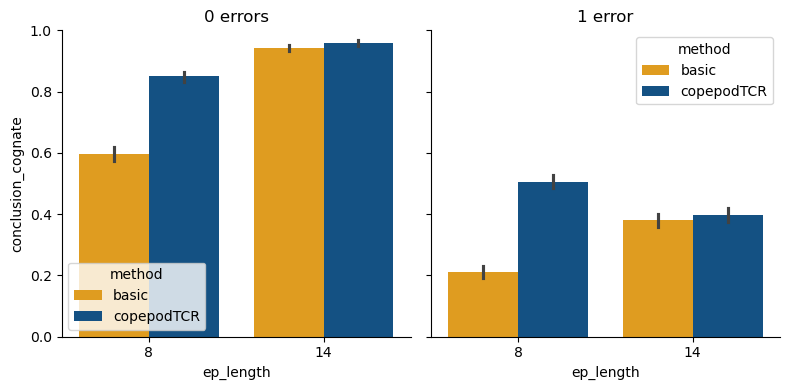

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

## choosing a subset of data with high activation signal (mu_signal = 45) and small overlap
## because then the length of the epitope will determine whether it is shared across peptides or not
## with ep_length = 8 => shared, eo_length = 14 => not-shared

## without errors
subset = table_noerror[(table_noerror['mu_signal'] == 45) & (table_noerror['shift'] == 4)]
ax = axes[0]
sn.barplot(data = subset, x = 'ep_length', y = 'conclusion_cognate', hue = 'method', palette = [color_basic, color_copepodTCR], ax = ax)
ax.set_title('0 errors')
plt.ylim(0, 1)

## with errors
subset = table_error[(table_error['mu_signal'] == 45) & (table_error['shift'] == 4)]
ax = axes[1]
sn.barplot(subset, x = 'ep_length', y = 'conclusion_cognate', hue = 'method', palette = [color_basic, color_copepodTCR], ax = ax)
ax.set_title('1 error')
plt.ylim(0, 1)

plt.tight_layout()
sn.despine()

# Figure 6B

Comparison of the simulated and experimental data. Kernel-density estimation plots show the distribution of the normalized activation signal. Simulated data shown for parameters: 3 replicates, 12 pools, peptide occurrence = 4, mu_signal = 5 or 45 , sigma_signal = 3, mu_neg = 0, sigma_neg = 3, sigma_pos_pools = 3, sigma_neg_pools = 3, sigma_pos_replicates = 3, sigma_neg_replicates = 3. Experimental activation signal was calculated from flow
cytometry read out (percentage of GFP-producing (activated) cells in the T cell activation assay) for T-cell
reporter cell lines expressing DPB1*04:(01/02)-restricted TCR6.3 or HLA-A02+ restricted YLQ-TCR1.

In [4]:
## common pooling parameters
n_pools = 12
### number of activated pools
pos_shape = 5
### number of activated pools with decreased signal
lowpos_shape = 0
### scaling factor for decreased signal, since here we don't decrease it, scaled signal = signal * 1
decreased_signal = 1

## common simulation parameters
sigma_signal = 3
mu_neg = 5
sigma_neg = 5
r = 3
### and the same numbers are used for sigma_pos_pools and sigma_neg_pools inside cpp.simulation function
sigma_pos_replicates = 3
sigma_neg_replicates = 3

## simulating data with high activation signal (mu_signal = 45)
mu_signal = 45
p_results1, pl_results1, n_results1, n_control1, means1 = cpp.simulation(mu_signal, sigma_signal, mu_neg, sigma_neg, r, sigma_pos_replicates, sigma_neg_replicates, n_pools, pos_shape, lowpos_shape, decreased_signal)
results1 = p_results1 + pl_results1 + n_results1
## normalization
results1 = results1/np.max(results1)

## simulating data with low activation signal (mu_signal = 5)
mu_signal = 5
p_results2, pl_results2, n_results2, n_control2, means2 = cpp.simulation(mu_signal, sigma_signal, mu_neg, sigma_neg, r, sigma_pos_replicates, sigma_neg_replicates, n_pools, pos_shape, lowpos_shape, decreased_signal)
results2 = p_results2 + pl_results2 + n_results2
## normalization
results2 = results2/np.max(results2)

## experimental data
exp_data_fc = pd.read_csv('./data/FC_TCR6_YLQ_activation.tsv',
                      sep = "\t")

## /100 because there are percentages
## TCR6_3
obs1 = np.array(exp_data_fc['TCR6_3_fc(%)'][exp_data_fc['type'] == 'pool'])/100
## normalization
obs1 = obs1/np.max(obs1)

## YLQ
obs2 = np.array(exp_data_fc['YLQ_TCR1_fc(%)'][exp_data_fc['type'] == 'pool'])/100
## normalization
obs2 = obs2/np.max(obs2)

Only 1 samples per chain. Reliable r-hat and ESS diagnostics require longer chains for accurate estimate.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [offset, n, n_pools, p_pools, pl_pools, p_pools_r, pl_pools_r, n_pools_r, n_control]


Output()

Sampling 2 chains for 1_000 tune and 1 draw iterations (2_000 + 2 draws total) took 6 seconds.
/Users/kovaleva/miniforge3/envs/copepodTCR/lib/python3.10/site-packages/arviz/data/base.py:272: UserWarning: More chains (2) than draws (1). Passed array should have shape (chains, draws, *shape)
  warnings.warn(
The number of samples is too small to check convergence reliably.
Only 1 samples per chain. Reliable r-hat and ESS diagnostics require longer chains for accurate estimate.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [offset, n, n_pools, p_pools, pl_pools, p_pools_r, pl_pools_r, n_pools_r, n_control]


Output()

Sampling 2 chains for 1_000 tune and 1 draw iterations (2_000 + 2 draws total) took 5 seconds.
/Users/kovaleva/miniforge3/envs/copepodTCR/lib/python3.10/site-packages/arviz/data/base.py:272: UserWarning: More chains (2) than draws (1). Passed array should have shape (chains, draws, *shape)
  warnings.warn(
The number of samples is too small to check convergence reliably.


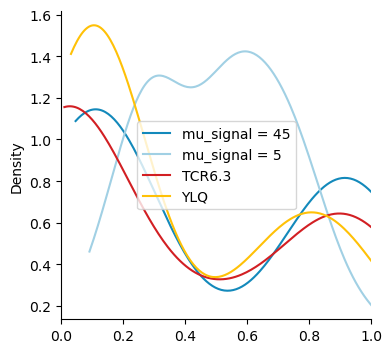

In [5]:
obs2 = obs2 / np.max(obs2)
fig, axes = plt.subplots(1, 1, figsize=(4, 4), sharey=True)

sn.kdeplot(results1, cut=0, label='mu_signal = 45', color = '#1389BB')
sn.kdeplot(results2, cut=0, label='mu_signal = 5', color = '#A1D0E4')
sn.kdeplot(obs1, cut=0, label='TCR6.3', color = '#D21F23')
sn.kdeplot(obs2, cut=0, label='YLQ', color = '#FFC107')
plt.xlim(0, 1)
plt.legend()
sn.despine()

plt.rcParams['svg.fonttype'] = 'none'